In [89]:
import sys
from pathlib import Path
import numpy as np
import time
import warnings
from tqdm.notebook import tqdm
from dataclasses import replace
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection
import colormaps as cmaps

ROOT = Path("/home/kzeleznikar/IJS-F1/Koda")
CFG = ROOT / "EI_cutoff" / "config" / "config_ibz.yaml"

# Ensure the root folder is in Python's search path
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from utils.cosmetics import apply_plt_style
from utils.plotting_utils import Plotter

apply_plt_style()
pt = Plotter(show=True, close=False)

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", dpi=300)
from utils.cosmetics import SET1_LIST
from utils.unit_converter import dimensionless_scales, to_si, energy_to_kelvin, freq_to_kelvin 

FIG_PATH = "/home/kzeleznikar/IJS-F1/Notes/latex/figures/"

In [90]:
dimensionless_scales(t_a_ev=0.1, a_0_angstrom=5.0, mass_u=20, c_s_si=2e3)

{'v_0': 75963.37239393132,
 'tau_0': 6.582119569509066e-15,
 'c': 3946.539609186049,
 'c_s': 0.02632847827803626,
 'omega_0': 0.1,
 'omega_0_si': 15192674478786.264,
 'L': 123984.19843320023,
 'L_si': 6.199209921660012e-05,
 'M': 11961.26670145533,
 'A_photon': 0.0029189410257200003,
 'A_phonon': 4.180159279778996e-05,
 'd': 0.09999999999999999}

In [91]:
import sys
import time
import warnings
import jax 
import matplotlib.pyplot as plt
import numpy as np

from EI_refactor.EI_ness import baths as B
from EI_refactor.EI_ness import model as M

BK = "gpu"
if BK == "gpu":
    from EI_refactor.EI_ness import gpu as S
else:
    from EI_refactor.EI_ness import cpu as S
 
from EI_refactor.EI_ness import cpu as C
from EI_refactor.EI_ness import gpu as G
 
warnings.simplefilter("ignore")
print("jax", jax.__version__, jax.devices())
md = M.Model(gap=4.0, ta=1.0, tb=-1.0, v=2.75) 
g = M.sgrid(240, 128)
e0 = M.solve_eq(md, g, 0.0, d=1.0)
tc = M.critical_temperature(md, g)
print(f"Delta_0 = {e0.d:.6f} = {energy_to_kelvin(e0.d):.6f} K, m_0 = {e0.m:.6f}, T_c = {energy_to_kelvin(tc):.6f} K")

jax 0.11.0 [CudaDevice(id=0)]
Delta_0 = 0.144946 = 168.203333 K, m_0 = -0.860828, T_c = 94.848349 K


In [92]:
print("omega_D =", freq_to_kelvin(0.026 * np.sqrt(4*np.pi), t_a_ev=0.2), "K")

omega_D = 213.9121174574206 K


In [93]:
md, g = M.Model(4.0, 1.0, -1.0, 2.75), M.sgrid(500, 128)
e0 = M.solve_eq(md, g, 0.0, d=1.0)
tc = M.critical_temperature(md, g)
st = M.mf(md, g, e0.d, e0.m)
ws, gam, dip, z0 = 2*e0.d, 0.003, 0.1, 4.0
amp = 2.0 * np.pi * B.ALPHA * 3946.54 * ws**2 * 0.039  # 2 pi alpha c ws^2 fr, SiC fr = 0.039
ph = lambda t: B.Chord(t, 0.026, 0.0, 4.2e-5, 1.0, -1.0)
sp = lambda t: B.SPP(t, ws, gam, amp, dip, z0)
ok = []

In [94]:
for name, bs in (("spp", [sp(tc)]), ("chord + spp", [ph(0.5 * tc), sp(tc)])):
    pk = B.pack(bs, md, g)
    rc = C.rates(md, g, st, pk)
    rg = np.asarray(G.rates(md, G.dev(g), st, G.dev(pk)))
    err = np.max(np.abs(rg - rc)) / np.max(rc)
    ok.append(err < 1.0e-10)
    print(f"1. {name:12s} max |gpu - cpu| / max cpu = {err:.1e}")
 

1. spp          max |gpu - cpu| / max cpu = 3.5e-13
1. chord + spp  max |gpu - cpu| / max cpu = 3.5e-13


In [95]:
pk = B.pack([sp(tc)], md, g)
gg, pg = G.dev(g), G.dev(pk)
rg = G.rates(md, gg, st, pg)
db = G.check_db(rg, st.e[:, g.wi].reshape(-1), tc)
ok.append(db < 1.0e-10)
print(f"2. detailed balance residual {db:.1e}")

2. detailed balance residual 2.8e-14


In [96]:

# 3. timing: first call compiles, later calls reuse; a new state must not recompile
t0 = time.time()
jax.block_until_ready(G.rates(md, gg, M.mf(md, g, 0.9 * e0.d, e0.m), pg))
t1 = time.time()
for f in (0.8, 0.7, 0.6):
    jax.block_until_ready(G.rates(md, gg, M.mf(md, g, f * e0.d, e0.m), pg))
t2 = time.time()
tc0 = time.time()
C.rates(md, g, st, pk)
print(f"3. gpu rates: new state {t1 - t0:.3f} s, then {(t2 - t1) / 3:.3f} s per call | cpu {time.time() - tc0:.3f} s")
 

3. gpu rates: new state 0.009 s, then 0.005 s per call | cpu 0.037 s


In [97]:

# 4. equal temperatures: NESS must be the equilibrium state at that temperature
t = 0.5 * tc
pk = B.pack([ph(t), sp(t)], md, g)
s = G.solve(md, g, pk, d=e0.d, m=e0.m)
eq = M.solve_eq(md, g, t, d=1.0)
dev_d = abs(float(s.d) - eq.d) / eq.d
ok.append(bool(s.ok) and dev_d < 1.0e-6)
print(f"4. T1 = T2 = 0.5 Tc: gpu ok={s.ok} d/D0={float(s.d) / e0.d:.6f}, equilibrium {eq.d / e0.d:.6f}")



4. T1 = T2 = 0.5 Tc: gpu ok=True d/D0=0.957394, equilibrium 0.957394


In [98]:
 
# 5. two temperatures: gpu and cpu NESS agree (values from the cpu run: 0.9338, 0.8074)
for t1 in (0.55, 0.7):
    pk = B.pack([ph(0.5 * tc), sp(t1 * tc)], md, g)
    sg = G.solve(md, g, pk, d=e0.d, m=e0.m)
    sc = C.solve(md, g, pk, d=e0.d, m=e0.m)
    dd = abs(float(sg.d) - sc.d) / sc.d
    ok.append(bool(sg.ok) and bool(sc.ok) and dd < 1.0e-6)
    print(f"5. T1 = {t1} Tc: gpu d/D0={float(sg.d) / e0.d:.6f} m={float(sg.m):.6f} | "
          f"cpu d/D0={sc.d / e0.d:.6f} m={sc.m:.6f} | rel diff {dd:.1e}")
 
print("ALL OK" if all(ok) else f"FAILED: {[i + 1 for i, x in enumerate(ok) if not x]}")


5. T1 = 0.55 Tc: gpu d/D0=0.936735 m=-0.861113 | cpu d/D0=0.936735 m=-0.861113 | rel diff 4.1e-16
5. T1 = 0.7 Tc: gpu d/D0=0.827655 m=-0.861537 | cpu d/D0=0.827655 m=-0.861537 | rel diff 2.7e-15
ALL OK


In [100]:
FIG_PATH = "/home/kzeleznikar/IJS-F1/Notes/latex/figures/"

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

... (11 outputs left out)

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

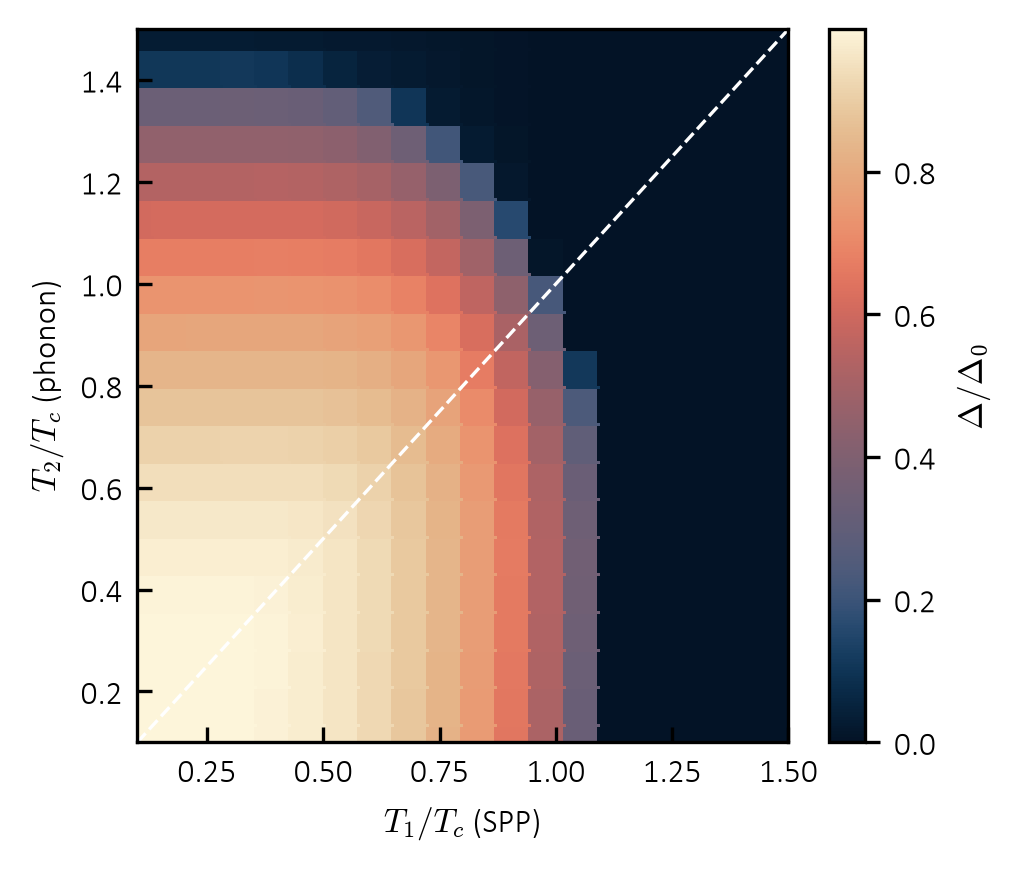

In [ ]:
md = M.Model(4.0, 1.0, -1.0, 4.1)  # BCS set
g = M.sgrid(200, 128)
# SPP: SiC like plateau, amp = 2 pi alpha c ws^2 fr
ws, gam, fr, dip, z0 = 2*e0.d, 0.05, 0.039, 0.1, 150.0
amp = 2.0 * np.pi * B.ALPHA * 3946.54 * ws**2 * fr 

cs, gph, aph = 0.026, 0.05, 4.2e-5
# temperature grid in units of Tc
t1n = np.linspace(0.1, 10.5, 10)  # SPP
t2n = np.linspace(0.1, 10.5, 10)  # phonons
 
e0 = M.solve_eq(md, g, 0.0, d=1.0)
tc = M.critical_temperature(md, g)
dd, mm, ok = (np.full((t2n.size, t1n.size), np.nan) for _ in range(3))
t0 = time.time()
for j, t2 in tqdm(enumerate(t2n)):
    d, m = None, None
    for i, t1 in tqdm(enumerate(t1n), leave=False):
        if d is None:  # start of a row: equilibrium at the colder bath
            eq = M.solve_eq(md, g, min(t1, t2) * tc, d=e0.d, m=e0.m)
            d, m = max(eq.d, 1.0e-3 * e0.d), eq.m
        pk = B.pack([B.Chord(t2 * tc, cs, gph, aph, 1.0, -1.0),
                     B.SPP(t1 * tc, ws, gam, amp, dip, z0)], md, g)
        try:
            s = S.solve(md, g, pk, d=d, m=m)
            if not s.ok:
                s = S.solve_fixed(md, g, pk, d=d, m=m)
        except ValueError as ex:
            print(f"T1={t1:.2f} T2={t2:.2f}: {ex}")
            continue
        dd[j, i], mm[j, i], ok[j, i] = float(s.d) / e0.d, float(s.m), float(s.ok)
        if s.ok and float(s.d) > 1.0e-3 * e0.d:  # continuation along the row
            d, m = float(s.d), float(s.m)
np.savez("scan_spp.npz", t1n=t1n, t2n=t2n, d=dd, m=mm, ok=ok, d0=e0.d, tc=tc,
         par=dict(md=md._asdict() if hasattr(md, "_asdict") else str(md), ws=ws, gam=gam, fr=fr,
                  dip=dip, z0=z0, cs=cs, gph=gph, aph=aph, ns=160, nf=256))
 
import matplotlib.pyplot as plt

h = 0.85
fig, ax = plt.subplots(figsize=(3.47412, h * 3.47412))
im = ax.pcolormesh(t1n, t2n, np.where(ok > 0, dd, np.nan), shading="auto", cmap=cmaps.lipari, vmin=0.0)
im.set_edgecolor("face")
cbar = plt.colorbar(im, ax=ax)
cbar.set_label(r"$\Delta/\Delta_0$", rotation=90, labelpad=5)
lo, hi = max(t1n.min(), t2n.min()), min(t1n.max(), t2n.max())
ax.plot([lo, hi], [lo, hi], "w--", lw=0.8)  # T1 = T2
ax.set_xlabel(r"$T_1/T_c$ (SPP)")
ax.set_ylabel(r"$T_2/T_c$ (phonon)")
ax.set_xlim(t1n.min(), t1n.max())
ax.set_ylim(t2n.min(), t2n.max())
ax.tick_params(which="both", direction="in")
plt.tight_layout()
# fig.savefig(FIG_PATH + "scan_spp_BEC.pdf", bbox_inches="tight")

In [127]:
md = M.Model(4.0, 1.0, -1.0, 4.1)  # BCS set
g = M.sgrid(500, 128)
e0 = M.solve_eq(md, g, 0.0, d=1.0)  # needed before ws
tc = M.critical_temperature(md, g)
# SPP plateau at the gap edge, amp = 2 pi alpha c ws^2 fr
ws, gam, fr, dip, z0 = 1.5 * e0.d, 0.05, 0.039, 0.1, 150.0
amp = 2.0 * np.pi * B.ALPHA * 3946.54 * ws**2 * fr
cs, gph, aph = 0.026, 0.05, 4.2e-5
t1n = np.linspace(0.1, 2.5, 20)  # SPP
t2n = np.linspace(0.1, 1.5, 20)  # phonons

In [128]:
from EI_refactor.EI_ness.teff import t_eff
from EI_refactor.EI_ness.cpu.rates import rates      
from matplotlib.ticker import SymmetricalLogLocator

T1 = 20.0 Tc, T2 = 0.1 Tc: ok = True, d/D0 = 0.0000, m = -0.9887, teff = 1.7750402306010202


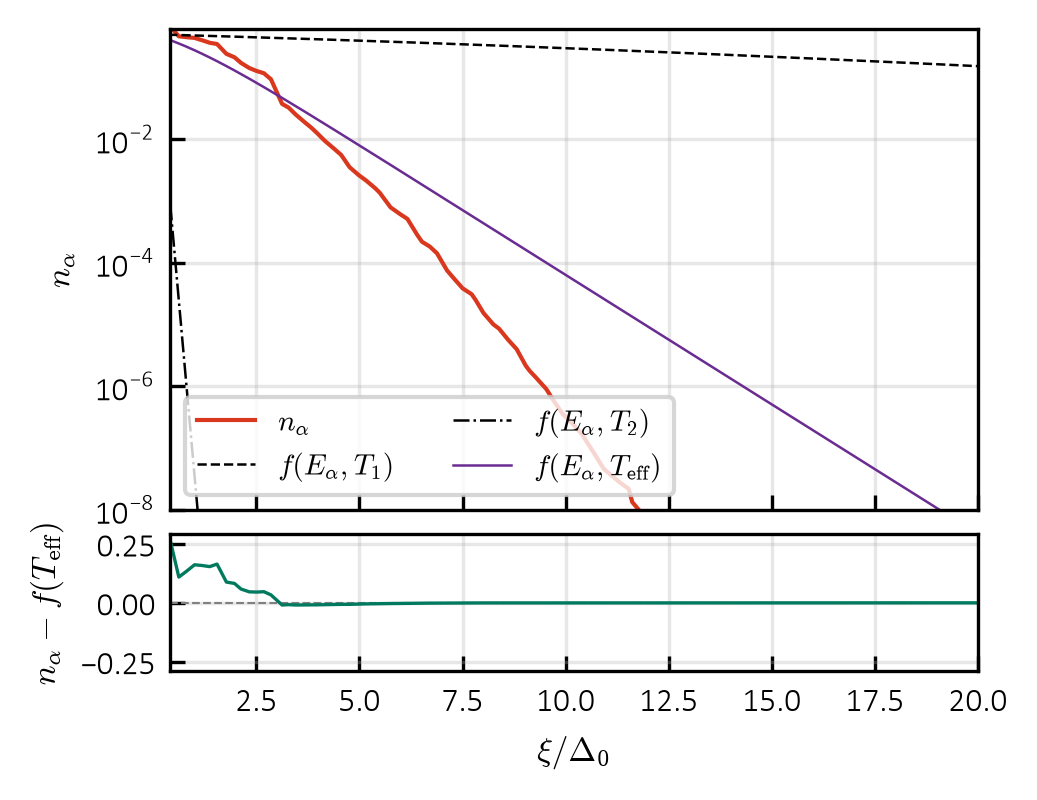

In [135]:
def probe(t1, t2):
    """NESS at (T1, T2) in units of Tc, SPP at T1, phonons at T2; plots n_alpha vs xi."""
    eq = M.solve_eq(md, g, min(t1, t2) * tc, d=e0.d, m=e0.m)  # start: colder bath
    pk = B.pack([B.Chord(t2 * tc, cs, gph, aph, 1.0, -1.0),
                 B.SPP(t1 * tc, ws, gam, amp, dip, z0)], md, g)
    s = S.solve(md, g, pk, d=max(eq.d, 1.0e-3 * e0.d), m=eq.m)
    if not s.ok:
        s = S.solve_fixed(md, g, pk, d=max(eq.d, 1.0e-3 * e0.d), m=eq.m)
    st = M.mf(md, g, float(s.d), float(s.m))
    xi = 0.5 * (st.e[0] - st.e[1]) * (st.u**2 - st.v**2)  # Hartree included
    na = np.asarray(s.n)[0]
    fd = lambda t: 1.0 / (1.0 + np.exp(st.e[0] / (t * tc)))  # mu = 0, shifted frame
    fig, (ax, ax2) = plt.subplots(2, 1, sharex=True, figsize=(3.47412, 0.8 * 3.47412), gridspec_kw={"height_ratios": [3.5, 1.0], "hspace": 0.08})
    ax.plot(xi / e0.d, na, "-", color="#D9381E", label=r"$n_\alpha$", lw=1)
    ax.plot(xi / e0.d, fd(t1), "k--", label=r"$f(E_\alpha, T_1)$", lw=0.6)
    ax.plot(xi / e0.d, fd(t2), "k-.", label=r"$f(E_\alpha, T_2)$", lw=0.6)
    te = t_eff(md, g, pk, rates, t1 * tc, t2 * tc, e0.d, e0.m)
    ax.plot(xi / e0.d, fd(te / tc), color="#6A2C91", label=r"$f(E_\alpha, T_\mathrm{eff})$", lw=0.6)

    ax.set_xlim(min(xi/e0.d), 20)
    ax.set_ylim(1e-8, 0.6)
    ax.set_yscale("log")
    ax.set_ylabel(r"$n_\alpha$")
    ax.grid(alpha=0.3)
    ax.tick_params(which="both", direction="in")
    ax.legend(fontsize=7, ncol=2)
    
    k = len(na)
    x2 = xi[:k] / e0.d
    diff = na - fd(te / tc)[:k] 
    ax2.axhline(0.0, color="0.5", lw=0.5, ls="--")
    ax2.plot(x2, diff, "-", color="#007A5E", lw=0.8)
    ax2.set_xlabel(r"$\xi/\Delta_0$")
    ax2.set_ylabel(r"$n_\alpha - f(T_\mathrm{eff})$", fontsize=8)
    ax2.grid(alpha=0.3)
    ax2.tick_params(which="both", direction="in")

    ymax = np.max(np.abs(diff[(x2 >= min(xi/e0.d)) & (x2 <= 8)]))
    ax2.set_ylim(-1.10 * ymax, 1.10 * ymax)

    plt.tight_layout()
    print(f"T1 = {t1} Tc, T2 = {t2} Tc: ok = {s.ok}, d/D0 = {float(s.d) / e0.d:.4f}, m = {float(s.m):.4f}, teff = {te/tc}")
    return s, fig

s, fig = probe(20., 0.1)
# fig.savefig(FIG_PATH + "0p8-0p4_NESS_SPP+phonon_BEC.pdf", bbox_inches="tight")

In [39]:

# md = M.Model(4.0, 1.0, -1.0, 2.75)
# t1, t2 = 2.0, 0.2                          # units of Tc
# gam, fr, dip, z0 = 0.05, 0.039, 0.1, 40.0
# cs, gph, aph = 0.026, 0.05, 4.2e-5
# amp = lambda ws: 2.0 * np.pi * B.ALPHA * 3946.54 * ws**2 * fr


# def point(ns, nf):
#     """Delta0 and NESS Delta on one grid."""
#     g = M.sgrid(ns, nf)
#     e0 = M.solve_eq(md, g, 0.0, d=1.0)
#     tc = M.critical_temperature(md, g)
#     ws = 2.0 * e0.d
#     pk = B.pack([B.Chord(t2 * tc, cs, gph, aph, 1.0, -1.0),
#                  B.SPP(t1 * tc, ws, gam, amp(ws), dip, z0)], md, g)
#     s = S.solve(md, g, pk, d=e0.d, m=e0.m)
#     if not s.ok:
#         s = S.solve_fixed(md, g, pk, d=e0.d, m=e0.m)
#     return e0.d, float(s.d), bool(s.ok)

#                        # fixed value in the other sweep
# nsarr = np.linspace(60, 300, 10)
# rs = np.array([point(120, int(n)) for n in tqdm(nsarr)])

In [40]:
# h = 0.6
# fig, ax = plt.subplots(1, 1, figsize=(3.47412, h * 3.47412))
# ax.plot(nsarr, rs[:, 1] / rs[:, 0], "o-", color=SET1_LIST[0], label=r"$\Delta/\Delta_0$")
# ax.set_ylabel(r"$\Delta$ (norm.)")
# ax.set_xlim(nsarr[0], nsarr[-1])
# ax.grid(alpha=0.3)
# ax.legend()
# ax.tick_params(which="both", direction="in")
# plt.tight_layout()
# plt.show()

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

211 s


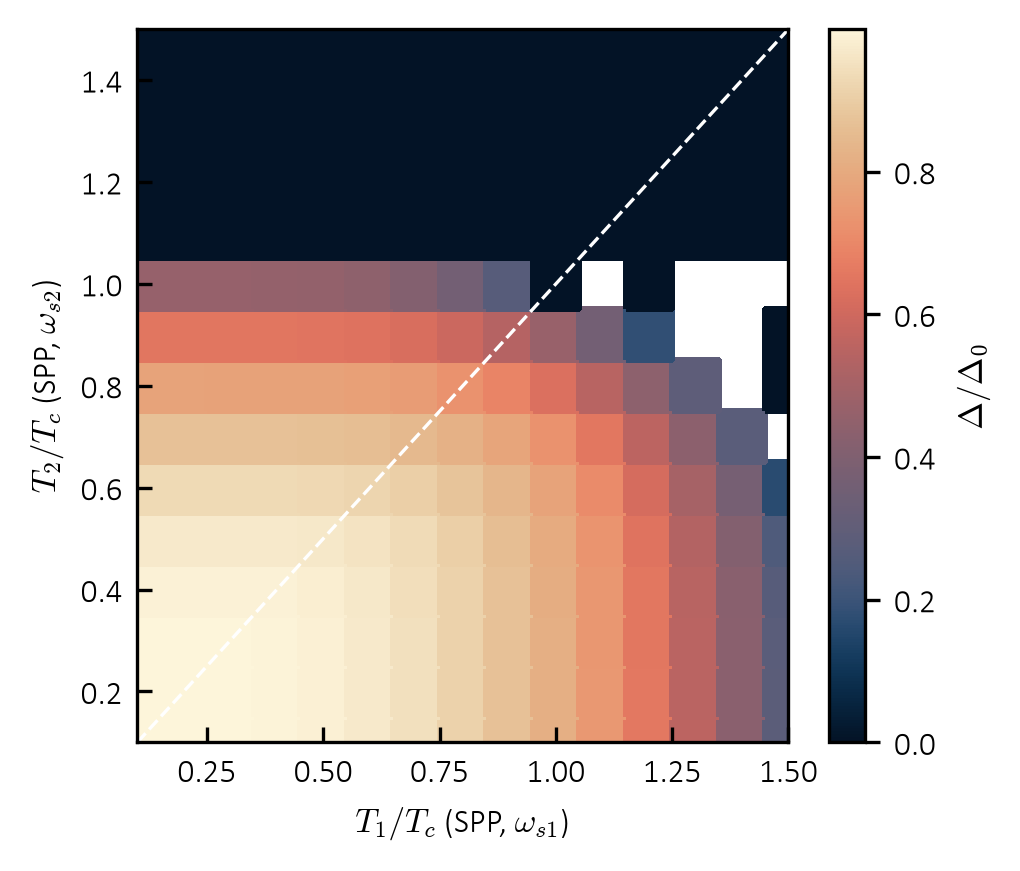

In [87]:
md = M.Model(4.0, 1.0, -1.0, 4.1)  # BEC set
g = M.sgrid(160, 128)
e0 = M.solve_eq(md, g, 0.0, d=1.0)
tc = M.critical_temperature(md, g)
# two SPP baths, amp = 2 pi alpha c ws^2 fr
gam, fr, dip, z0 = 0.05, 0.039, 10.1, 40.0
ws1, ws2 = 2.0 * e0.d, 8.0 * e0.d  # bath 1 at T1, bath 2 at T2
amp = lambda ws: 2.0 * np.pi * B.ALPHA * 3946.54 * ws**2 * fr
PH = False  # True: add the Chord phonon at T2 (extra intraband channel)
cs, gph, aph = 0.026, 0.05, 4.2e-5
t1n = np.linspace(0.1, 1.5, 15)  # SPP 1
t2n = np.linspace(0.1, 1.5, 15)  # SPP 2
dd, mm, ok = (np.full((t2n.size, t1n.size), np.nan) for _ in range(3))
t0 = time.time()
for j, t2 in tqdm(enumerate(t2n), total=t2n.size):
    d, m = None, None
    for i, t1 in tqdm(enumerate(t1n), total=t1n.size, leave=False):
        if d is None:  # start of a row: equilibrium at the colder bath
            eq = M.solve_eq(md, g, min(t1, t2) * tc, d=e0.d, m=e0.m)
            d, m = max(eq.d, 1.0e-3 * e0.d), eq.m
        bl = [B.SPP(t1 * tc, ws1, gam, amp(ws1), dip, 4*z0),
              B.SPP(t2 * tc, ws2, gam, amp(ws2), dip, z0)]
        if PH:
            bl.append(B.Chord(t2 * tc, cs, gph, aph, 1.0, -1.0))
        pk = B.pack(bl, md, g)
        try:
            s = S.solve(md, g, pk, d=d, m=m)
            if not s.ok:
                s = S.solve_fixed(md, g, pk, d=d, m=m)
        except ValueError as ex:
            print(f"T1={t1:.2f} T2={t2:.2f}: {ex}")
            continue
        dd[j, i], mm[j, i], ok[j, i] = float(s.d) / e0.d, float(s.m), float(s.ok)
        if s.ok and float(s.d) > 1.0e-3 * e0.d:  # continuation along the row
            d, m = float(s.d), float(s.m)
print(f"{time.time() - t0:.0f} s")


h = 0.85
fig, ax = plt.subplots(figsize=(3.47412, h * 3.47412))
im = ax.pcolormesh(t1n, t2n, np.where(ok > 0, dd, np.nan), shading="auto", cmap=cmaps.lipari, vmin=0.0)
im.set_edgecolor("face")
cbar = plt.colorbar(im, ax=ax)
cbar.set_label(r"$\Delta/\Delta_0$", rotation=90, labelpad=5)
lo, hi = max(t1n.min(), t2n.min()), min(t1n.max(), t2n.max())
ax.plot([lo, hi], [lo, hi], "w--", lw=0.8)  # T1 = T2
ax.set_xlabel(r"$T_1/T_c$ (SPP, $\omega_{s1}$)")
ax.set_ylabel(r"$T_2/T_c$ (SPP, $\omega_{s2}$)")
ax.set_xlim(t1n.min(), t1n.max())
ax.set_ylim(t2n.min(), t2n.max())
ax.tick_params(which="both", direction="in")
plt.tight_layout()